# 09 Test errors

We wrote this notebook after seeing the results of notebook 08, to understand them. Nothing here changes the model, the features, the calibrator or the main number, which stays AUC 0.692 on all test rows. Any number that leaves out a season or a year is an explanation and does not replace it.

As in notebook 05, fields known only after the climb (`TERMREASON`, `TERMNOTE`) help explain errors and are never used as features. `gap` is the predicted minus the actual share of summits, so a positive gap means the model was too optimistic. No individual climbers are listed.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

from src import models as M
from src.config import PROCESSED_DIR, TABLES_DIR, TARGET
from src.data_dictionary import parse_guide
from src.error_analysis import season_gaps
from src.evaluate import evaluate, fmt
from src.explain import FEATURE_GROUPS, shap_values
from src.features import to_number
from src.leakage_audit import with_post_climb_fields
from src.split import fit_frame, load_features, time_split
from src.style import BLUE, GRID, INK, ORANGE, apply_style, save_figure

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
apply_style()

final = M.load_final_config()
exped = pd.read_parquet(PROCESSED_DIR / "exped.parquet")
members = pd.read_parquet(PROCESSED_DIR / "members.parquet")
peaks = pd.read_parquet(PROCESSED_DIR / "peaks.parquet")
train, val, test = time_split(load_features())
train_fit = fit_frame(train)
val = with_post_climb_fields(val, exped, members)
test = with_post_climb_fields(test, exped, members)
clean_val = ~val["ANOMALOUS_SEASON"].to_numpy(dtype=bool)
PEAK_NAMES = {**peaks.set_index("PEAKID")["PKNAME"].to_dict(), "OTHER": "Other peaks"}

model = M.refit_lightgbm(train_fit, final["iterations"], params=final["params"], features=final["features"], seeds=tuple(final["seeds"]))
y_val, y = M.target(val), M.target(test)
p_val_raw, p_raw = model.predict(val), model.predict(test)
calibrator = M.Calibrator("platt").fit(p_val_raw[clean_val], y_val[clean_val])
p = calibrator.predict(p_raw)
p_val = M.crossfit_calibrate(val, p_val_raw, "platt", fit_rows=clean_val)
test_auc = roc_auc_score(y, p_raw)
saved = pd.read_csv(TABLES_DIR / "08_test_metrics.csv")["roc_auc"].iloc[0]
print(f"test AUC {test_auc:.4f}, notebook 08: {saved}")
assert saved.startswith(f"{test_auc:.3f}")

test AUC 0.6920, notebook 08: 0.692 [0.673, 0.709]


## 1. Seasons with the largest misses
One peak in one season, with at least 30 climbers, as in notebook 05. `conditions` is the share of rows whose expedition ended because of bad conditions or bad weather (`TERMREASON` 4 or 5), and `foresummit` is the share that ended at a subpeak or foresummit (`TERMREASON` 2).

seasons with at least 30 climbers: 56; gap above +20 pp: 9; below -20 pp: 3
Worse than expected:


,name,PEAK_GROUP,YEAR,SEASON,n,expeditions,mean_y,mean_p,gap,foresummit,conditions
0,Ama Dablam,AMAD,2025,Spring,106,10,0.179,0.657,0.477,0.000,0.509
1,Manaslu,MANA,2022,Autumn,408,40,0.184,0.652,0.468,0.032,0.328
2,Kangchenjunga,KANG,2024,Spring,34,3,0.147,0.531,0.384,0.000,0.500
3,Ama Dablam,AMAD,2022,Spring,91,11,0.198,0.572,0.375,0.000,0.132
4,Ama Dablam,AMAD,2024,Spring,100,9,0.360,0.663,0.303,0.000,0.030
5,Ama Dablam,AMAD,2023,Spring,78,8,0.231,0.528,0.298,0.000,0.077
6,Himlung Himal,HIML,2023,Spring,40,3,0.225,0.465,0.240,0.000,0.325
7,Dhaulagiri I,DHA1,2022,Autumn,31,3,0.000,0.238,0.238,0.000,1.000


Better than expected:


,name,PEAK_GROUP,YEAR,SEASON,n,expeditions,mean_y,mean_p,gap,foresummit,conditions
55,Cho Oyu,CHOY,2025,Autumn,49,7,0.918,0.519,-0.400,0.000,0.000
54,Makalu,MAKA,2022,Spring,51,6,0.863,0.523,-0.339,0.000,0.000
53,Cho Oyu,CHOY,2023,Autumn,50,7,0.860,0.586,-0.274,0.000,0.000
52,Kangchenjunga,KANG,2025,Spring,76,6,0.763,0.574,-0.189,0.000,0.000
51,Cho Oyu,CHOY,2024,Autumn,33,7,0.636,0.461,-0.175,0.000,0.000
50,Manaslu,MANA,2025,Autumn,383,29,0.846,0.675,-0.171,0.063,0.044
49,Baruntse,BARU,2024,Autumn,52,7,0.442,0.284,-0.158,0.000,0.000
48,Annapurna I,ANN1,2023,Spring,57,8,0.632,0.505,-0.126,0.000,0.035


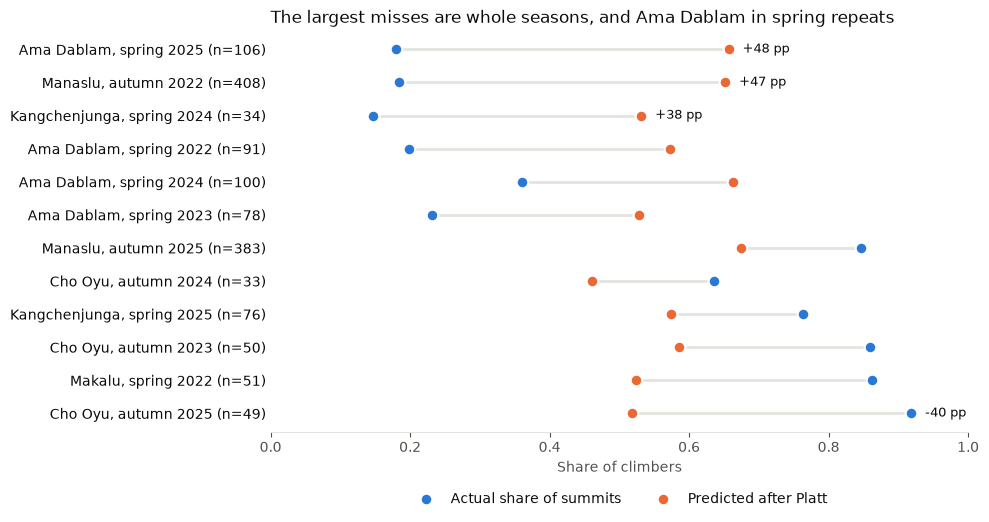

In [2]:
seasons = {"1": "Spring", "2": "Summer", "3": "Autumn", "4": "Winter"}
reasons = to_number(test["TERMREASON"])
season_groups = [test["PEAK_GROUP"].astype(str), to_number(test["YEAR"]).astype(int), test["SEASON"].astype(int)]
foresummit = (reasons == 2).groupby(season_groups).mean()
conditions = reasons.isin([4, 5]).groupby(season_groups).mean()
gaps = season_gaps(test, p)
gaps.insert(0, "name", [PEAK_NAMES.get(k, k) for k in gaps["PEAK_GROUP"]])
keys = [(peak, int(year), int(season)) for peak, year, season in zip(gaps["PEAK_GROUP"].astype(str), gaps["YEAR"], gaps["SEASON"])]
gaps["foresummit"] = [foresummit.get(key) for key in keys]
gaps["conditions"] = [conditions.get(key) for key in keys]
gaps["SEASON"] = gaps["SEASON"].astype(str).map(seasons)
gaps.round(3).to_csv(TABLES_DIR / "09_season_gaps.csv", index=False)
print(f"seasons with at least 30 climbers: {len(gaps)}; gap above +20 pp: {int((gaps['gap'] > 0.2).sum())}; below -20 pp: {int((gaps['gap'] < -0.2).sum())}")
print("Worse than expected:")
display(gaps.head(8).round(3))
print("Better than expected:")
display(gaps.tail(8).iloc[::-1].round(3))

shown = pd.concat([gaps.head(6), gaps.tail(6)]).sort_values("gap")
fig, ax = plt.subplots(figsize=(9, 5.2))
rows = np.arange(len(shown))
ax.hlines(rows, shown["mean_y"], shown["mean_p"], color=GRID, lw=2, zorder=1)
ax.scatter(shown["mean_y"], rows, s=70, color=BLUE, edgecolors="white", linewidths=1.5, zorder=3, label="Actual share of summits")
ax.scatter(shown["mean_p"], rows, s=70, color=ORANGE, edgecolors="white", linewidths=1.5, zorder=3, label="Predicted after Platt")
ax.set_yticks(rows, [f"{name}, {season.lower()} {int(year)} (n={int(n):,})" for name, season, year, n in zip(shown["name"], shown["SEASON"], shown["YEAR"], shown["n"])], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of climbers")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
for row, key in zip(rows, shown.index):
    if key in shown["gap"].abs().sort_values(ascending=False).index[:4]:
        ax.text(max(shown.loc[key, "mean_y"], shown.loc[key, "mean_p"]) + 0.02, row, f"{100 * shown.loc[key, 'gap']:+.0f} pp", va="center", color=INK, fontsize=9)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, labelcolor=INK)
ax.set_title("The largest misses are whole seasons, and Ama Dablam in spring repeats", loc="left", fontsize=12)
save_figure(fig, "09_season_misses.png")
plt.show()

## 2. Manaslu in autumn
The largest miss on validation was also Manaslu in autumn, in 2021, and it came from expeditions recorded at a foresummit. We check whether 2022 looks the same.

In [3]:
later = pd.concat([val.assign(p=p_val), test.assign(p=p)], ignore_index=True)
later_reasons = to_number(later["TERMREASON"])
later = later.assign(y=later[TARGET].astype(float), foresummit=later_reasons == 2, conditions=later_reasons.isin([4, 5]))
manaslu = later[(later["PEAKID"] == "MANA") & (later["SEASON"] == 3)].groupby("YEAR").agg(
    rows=("y", "size"), expeditions=("EXPID", "nunique"), actual=("y", "mean"), predicted=("p", "mean"), foresummit=("foresummit", "mean"), conditions=("conditions", "mean"))
manaslu.round(3).to_csv(TABLES_DIR / "09_manaslu_autumn.csv")
display(manaslu.round(3))

manaslu_2022 = ((test["PEAKID"] == "MANA") & (test["SEASON"] == 3) & (test["YEAR"] == 2022)).to_numpy(dtype=bool)
codes = parse_guide()[("exped", "TERMREASON")]["codes"]
endings = test[manaslu_2022].assign(reason=reasons[manaslu_2022].map(lambda c: codes.get(int(c), "Unknown") if pd.notna(c) else "Unknown")).groupby("reason").agg(
    rows=(TARGET, "size"), expeditions=("EXPID", "nunique"), success=(TARGET, lambda s: s.astype(float).mean())).sort_values("rows", ascending=False)
endings.round(3).to_csv(TABLES_DIR / "09_manaslu_2022_endings.csv")
display(endings.round(3))

ids = test.loc[manaslu_2022, "EXPID"].unique()
notes = exped[exped["EXPID"].isin(ids) & (exped["YEAR"] == 2022)]["TERMNOTE"]
print(f"expeditions {len(ids)}, with a termination note {int((notes.fillna('') != '').sum())}, mentioning avalanches {int(notes.str.contains('avalanch', case=False, na=False).sum())}")

,rows,expeditions,actual,predicted,foresummit,conditions
YEAR,,,,,,
2018,198,30,0.768,0.478,0.000,0.051
2019,254,47,0.740,0.652,0.000,0.031
2020,18,1,0.722,0.175,0.000,0.000
2021,189,21,0.063,0.520,0.878,0.000
2022,408,40,0.184,0.652,0.032,0.328
2023,307,21,0.782,0.679,0.000,0.000
2024,309,25,0.650,0.674,0.000,0.000
2025,383,29,0.846,0.675,0.063,0.044


,rows,expeditions,success
reason,,,
Success (main peak),261,22,0.284
"Bad conditions (deep snow, avalanching, falling ice, or rock)",107,14,0.000
"Bad weather (storms, high winds)",27,3,0.000
"Success (subpeak, foresummit)",13,1,0.077


expeditions 40, with a termination note 14, mentioning avalanches 9


## 3. Ama Dablam in spring
Spring on Ama Dablam is among the largest misses in all four test years, so this one is not a single bad season. We compare it with autumn on the same peak and use the peak x season rule as a reference. Predictions for 1990-2017 are on rows the model was fitted on. Then we look at how these teams changed and which groups of features moved the prediction, in log-odds.

In [4]:
rule = M.PeakSeasonRate().fit(train_fit)
periods = (("1990-2017", train_fit, calibrator.predict(model.predict(train_fit))), ("2018-2021", val, p_val), ("2022-2025", test, p))
rows, teams, effects = [], {}, {}
for period, frame, q in periods:
    truth, q_rule = M.target(frame), rule.predict(frame)
    for code, name in ((1, "Spring"), (3, "Autumn")):
        part = ((frame["PEAKID"] == "AMAD") & (frame["SEASON"] == code)).to_numpy(dtype=bool)
        rows.append({"period": period, "season": name, "rows": int(part.sum()), "expeditions": frame.loc[part, "EXPID"].nunique(), "actual": truth[part].mean(), "predicted": q[part].mean(), "rule": q_rule[part].mean()})
    spring = ((frame["PEAKID"] == "AMAD") & (frame["SEASON"] == 1)).to_numpy(dtype=bool)
    teams[period] = {column: to_number(frame.loc[spring, column]).median() for column in ("TOTMEMBERS", "TOTHIRED", "HIRED_PER_MEMBER", "CROWD_ROUTE")}
    spring_shap, _ = shap_values(model, frame[spring])
    effects[period] = {**{group: spring_shap[columns].sum(axis=1).mean() for group, columns in FEATURE_GROUPS.items()}, "all features": spring_shap.sum(axis=1).mean()}
ama_dablam = pd.DataFrame(rows).set_index(["period", "season"])
ama_dablam.round(3).to_csv(TABLES_DIR / "09_ama_dablam_seasons.csv")
display(ama_dablam.round(3))
print("Spring teams, medians:")
pd.DataFrame(teams).round(3).to_csv(TABLES_DIR / "09_ama_dablam_spring_teams.csv")
display(pd.DataFrame(teams).round(3))
print("Spring rows, mean SHAP by group:")
pd.DataFrame(effects).round(3).to_csv(TABLES_DIR / "09_ama_dablam_spring_shap.csv")
display(pd.DataFrame(effects).round(3))

ama_spring = ((test["PEAKID"] == "AMAD") & (test["SEASON"] == 1)).to_numpy(dtype=bool)
print(f"test AUC without Ama Dablam in spring ({int(ama_spring.sum())} rows): {roc_auc_score(y[~ama_spring], p_raw[~ama_spring]):.3f}")

rows  expeditions  actual  predicted   rule
period    season                                             
1990-2017 Spring   668          179   0.289      0.411  0.296
          Autumn  4656          954   0.555      0.612  0.555
2018-2021 Spring    97           23   0.351      0.418  0.296
          Autumn   921          161   0.560      0.595  0.555
2022-2025 Spring   375           38   0.243      0.611  0.296
          Autumn  1964          159   0.578      0.623  0.555

Spring teams, medians:


,1990-2017,2018-2021,2022-2025
TOTMEMBERS,5.0,11.000,12.000
TOTHIRED,0.0,3.000,7.000
HIRED_PER_MEMBER,0.0,0.364,0.692
CROWD_ROUTE,26.0,39.000,84.000


Spring rows, mean SHAP by group:


,1990-2017,2018-2021,2022-2025
Age,0.033,-0.029,-0.039
Experience,-0.058,-0.036,-0.076
Hired staff and team size,-0.072,-0.024,0.092
Crowding,-0.308,-0.261,0.299
Season,-0.035,-0.029,-0.025
Peak and route,0.439,0.391,0.500
Person,0.040,0.044,-0.005
Agency,-0.022,-0.032,-0.031
all features,0.016,0.023,0.714


test AUC without Ama Dablam in spring (375 rows): 0.700


## 4. How much one season can move the AUC
Leaving out a bad season always makes the number look better, so we leave out every peak x year x season group in turn and look at both ends of the list.

In [5]:
season_key = (test["PEAK_GROUP"].astype(str) + " " + test["YEAR"].astype(str) + " " + test["SEASON"].astype(str).map(seasons)).to_numpy()
rows = []
for key in np.unique(season_key):
    kept = season_key != key
    rows.append({"season": key, "rows": int((~kept).sum()), "auc_without": roc_auc_score(y[kept], p_raw[kept]), "change": roc_auc_score(y[kept], p_raw[kept]) - test_auc})
influence = pd.DataFrame(rows).sort_values("change", ascending=False).set_index("season")
influence.round(4).to_csv(TABLES_DIR / "09_leave_one_season_out.csv")
print("AUC rises most without:")
display(influence.head(5).round(4))
print("AUC falls most without:")
display(influence.tail(5).iloc[::-1].round(4))

year_2022 = (test["YEAR"] == 2022).to_numpy(dtype=bool)
print(f"2022 AUC {roc_auc_score(y[year_2022], p_raw[year_2022]):.3f}; without Manaslu autumn 2022 {roc_auc_score(y[year_2022 & ~manaslu_2022], p_raw[year_2022 & ~manaslu_2022]):.3f}, actual {y[year_2022 & ~manaslu_2022].mean():.3f}, predicted {p[year_2022 & ~manaslu_2022].mean():.3f}")

AUC rises most without:


,rows,auc_without,change
season,,,
MANA 2022 Autumn,408,0.7045,0.0125
AMAD 2025 Autumn,501,0.6976,0.0055
AMAD 2025 Spring,106,0.6961,0.0041
EVER 2023 Spring,486,0.6961,0.0041
AMAD 2022 Autumn,481,0.6959,0.0039


AUC falls most without:


,rows,auc_without,change
season,,,
MANA 2025 Autumn,383,0.6872,-0.0048
EVER 2024 Spring,474,0.6880,-0.0040
MANA 2023 Autumn,307,0.6882,-0.0038
EVER 2022 Spring,345,0.6884,-0.0037
OTHER 2022 Autumn,142,0.6899,-0.0022


2022 AUC 0.679; without Manaslu autumn 2022 0.731, actual 0.497, predicted 0.539


## 5. Platt by period
Platt scaling was learned on non-anomalous validation rows, where the model predicted too low, so it moves predictions up. Here we see how that worked out in each test year.

In [6]:
def platt_row(name, truth, before, after, mask):
    return {"period": name, "rows": int(mask.sum()), "actual": truth[mask].mean(), "before_platt": before[mask].mean(), "after_platt": after[mask].mean(),
            "brier_before": brier_score_loss(truth[mask], before[mask]), "brier_after": brier_score_loss(truth[mask], after[mask]),
            "log_loss_before": log_loss(truth[mask], before[mask]), "log_loss_after": log_loss(truth[mask], after[mask])}

print(f"Platt: slope {calibrator.m.coef_[0, 0]:.3f}, intercept {calibrator.m.intercept_[0]:.3f}")
test_year = test["YEAR"].astype(int).to_numpy()
rows = [platt_row("validation, non-anomalous, out of fold", y_val, p_val_raw, p_val, clean_val),
        platt_row("test, all rows", y, p_raw, p, np.ones(len(y), dtype=bool))]
rows += [platt_row(str(year), y, p_raw, p, test_year == year) for year in np.unique(test_year)]
rows += [platt_row("2023-2025", y, p_raw, p, test_year >= 2023),
         platt_row("test without Manaslu autumn 2022", y, p_raw, p, ~manaslu_2022)]
platt = pd.DataFrame(rows).set_index("period")
platt.round(4).to_csv(TABLES_DIR / "09_platt_by_period.csv")
display(platt.round(4))

Platt: slope 1.234, intercept 0.279


,rows,actual,before_platt,after_platt,brier_before,brier_after,log_loss_before,log_loss_after
period,,,,,,,,
"validation, non-anomalous, out of fold",4236,0.5489,0.4913,0.5501,0.2099,0.2060,0.6078,0.5978
"test, all rows",9114,0.5269,0.5146,0.5783,0.2214,0.2240,0.6338,0.6400
2022,2186,0.4382,0.5000,0.5602,0.2255,0.2381,0.6401,0.6700
2023,2203,0.5488,0.5085,0.5715,0.2225,0.2214,0.6369,0.6349
2024,2196,0.5587,0.5173,0.5819,0.2192,0.2179,0.6303,0.6274
2025,2529,0.5567,0.5301,0.5969,0.2190,0.2194,0.6285,0.6297
2023-2025,6928,0.5548,0.5192,0.5840,0.2202,0.2195,0.6318,0.6306
test without Manaslu autumn 2022,8706,0.5430,0.5117,0.5749,0.2181,0.2177,0.6266,0.6259


## 6. Agencies the model has not seen
About a third of the test rows have an agency that did not appear up to 2017. They reach the model as missing values, so we check whether these rows are ranked worse.

In [7]:
seen = M.fit_categories(train_fit, final["features"])["AGENCY"]
rows = []
for split, frame, truth, q in (("validation", val, y_val, p_val_raw), ("test", test, y, p_raw)):
    new = (~M._cat(frame["AGENCY"]).isin(seen)).to_numpy()
    for label, part in (("seen up to 2017", ~new), ("new", new)):
        rows.append({"split": split, "agency": label, "rows": int(part.sum()), "expeditions": frame.loc[part, "EXPID"].nunique(), "actual": round(truth[part].mean(), 3), "predicted": round(q[part].mean(), 3),
                     "roc_auc": fmt(evaluate(truth[part], q[part], frame.loc[part, "EXPID"].to_numpy(), n_boot=1000))["roc_auc"]})
agencies = pd.DataFrame(rows).set_index(["split", "agency"])
agencies.to_csv(TABLES_DIR / "09_new_agencies.csv")
display(agencies)

rows  expeditions  actual  predicted               roc_auc
split      agency                                                                     
validation seen up to 2017  3807          631   0.529      0.496  0.710 [0.676, 0.744]
           new              1235          291   0.561      0.498  0.716 [0.673, 0.758]
test       seen up to 2017  5992          647   0.514      0.511  0.689 [0.666, 0.711]
           new              3122          380   0.552      0.522  0.697 [0.664, 0.724]

## 7. LightGBM and logistic regression by year
On validation LightGBM ranked climbers better than logistic regression, and on the test years the difference is no longer reliable. Predictions are before calibration.

In [8]:
logreg = M.fit_logreg(train_fit)
rows = []
for frame, truth, lgbm, other in ((val, y_val, p_val_raw, logreg.predict(val)), (test, y, p_raw, logreg.predict(test))):
    frame_year = frame["YEAR"].astype(int).to_numpy()
    for year in np.unique(frame_year):
        s = frame_year == year
        rows.append({"year": year, "rows": int(s.sum()), "actual": truth[s].mean(), "lightgbm_mean": lgbm[s].mean(), "logreg_mean": other[s].mean(),
                     "lightgbm_auc": roc_auc_score(truth[s], lgbm[s]), "logreg_auc": roc_auc_score(truth[s], other[s]),
                     "lightgbm_log_loss": log_loss(truth[s], lgbm[s]), "logreg_log_loss": log_loss(truth[s], other[s])})
by_year = pd.DataFrame(rows).set_index("year")
by_year.round(3).to_csv(TABLES_DIR / "09_logreg_by_year.csv")
display(by_year.round(3))

,rows,actual,lightgbm_mean,logreg_mean,lightgbm_auc,logreg_auc,lightgbm_log_loss,logreg_log_loss
year,,,,,,,,
2018,1708,0.578,0.494,0.531,0.737,0.711,0.609,0.632
2019,1833,0.597,0.509,0.547,0.741,0.702,0.602,0.629
2020,136,0.699,0.413,0.511,0.609,0.648,0.792,0.719
2021,1365,0.387,0.491,0.528,0.675,0.654,0.648,0.716
2022,2186,0.438,0.500,0.582,0.679,0.679,0.640,0.723
2023,2203,0.549,0.508,0.609,0.691,0.661,0.637,0.702
2024,2196,0.559,0.517,0.614,0.703,0.694,0.630,0.667
2025,2529,0.557,0.530,0.656,0.694,0.694,0.629,0.701


## 8. Peaks on validation and test
The ranking inside one peak is weaker on the test years. These tables put both periods side by side, from the results of notebooks 05 and 08.

In [9]:
val_peaks = pd.read_csv(TABLES_DIR / "05_by_peak.csv", index_col="PEAK_GROUP")
test_peaks = pd.read_csv(TABLES_DIR / "08_by_peak.csv", index_col="PEAK_GROUP")
compared = val_peaks[["name", "n", "roc_auc", "gap"]].merge(test_peaks[["n", "roc_auc", "gap"]], left_index=True, right_index=True, suffixes=("_val", "_test")).sort_values("n_test", ascending=False)
compared.to_csv(TABLES_DIR / "09_peaks_compared.csv")
display(compared)
display(pd.concat({"validation": pd.read_csv(TABLES_DIR / "05_inside_groups.csv", index_col="level")["auc"],
                   "test": pd.read_csv(TABLES_DIR / "08_inside_groups.csv", index_col="level")["auc"]}, axis=1))

,name,n_val,roc_auc_val,gap_val,n_test,roc_auc_test,gap_test
PEAK_GROUP,,,,,,,
AMAD,Ama Dablam,1041,0.655,0.034,2378,0.615,0.097
EVER,Everest,1510,0.707,0.046,1875,0.630,-0.009
MANA,Manaslu,687,0.678,0.008,1425,0.669,0.073
HIML,Himlung Himal,262,0.621,0.020,734,0.664,0.070
OTHER,Other peaks,439,0.717,-0.006,687,0.650,0.078
LHOT,Lhotse,263,0.544,0.113,481,0.662,0.083
MAKA,Makalu,98,0.766,-0.115,275,0.692,0.017
BARU,Baruntse,101,0.817,0.021,229,0.568,0.074
KANG,Kangchenjunga,79,0.510,-0.130,219,0.712,-0.011


,validation,test
level,,
all rows (pooled),0.712,0.692
inside one peak,0.677,0.638
inside one peak x year x season,0.672,0.645
inside one expedition,0.657,0.644
